# Lab 13 — Validating a Clinical Prediction Model

**AI in Healthcare · Unit IV · B.Tech AI, Third Year · About 120 minutes**
**Lecture:** [Session 3 — Model validation, performance assessment, and challenges in healthcare data](../lectures/session-03-validation-performance.md)
**Previous lab:** [Lab 12 — Training an imaging model](lab-12-imaging-model-training.ipynb)
**Runs on:** any laptop CPU; no GPU or API needed.

## Objectives

In Session 3 you saw validation results. In this lab you produce them yourself and learn which choices make them honest or misleading:

1. **Split by the right unit.** Compare row-level and patient-level cross-validation on data where patients have many visits.
2. **Validate over time.** Train on earlier visits, test on later ones, and find out why the model's risks drifted.
3. **Validate externally.** Test a Cleveland heart-disease model at three other hospitals: discrimination, calibration, and threshold metrics with uncertainty.
4. **Recalibrate** the model for one hospital using part of its data, and check the result on the rest.
5. **Audit subgroups and errors**, and write a short validation report.

**Prerequisites:** Session 3 lecture notes; Lab 4 (logistic regression, sensitivity, specificity, PPV, NPV, AUROC). Basic pandas: filtering with masks, `groupby`. No medical knowledge is needed.

## Two datasets

| | Part 1–2: synthetic clinic visits | Parts 3–4: UCI Heart Disease |
|---|---|---|
| Source | **Hand-written generator in this notebook** (not Synthea, not real patients) | UCI Machine Learning Repository, four hospitals, CC BY 4.0 ([doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X)) |
| One row is | One clinic **visit**; each patient has 3–12 visits | One **patient** |
| Prediction target | Unplanned hospital admission within 90 days after the visit | Coronary heart disease on angiography (more than 50% narrowing of a major artery) |
| Why we use it | It has patient IDs and dates, so patient-level and temporal splits are possible | It has four real sites, so external validation is possible |

The synthetic data contain **deliberately planted features** that make validation mistakes visible. They are revealed during the lab. Synthetic results show how validation *methods* behave; they say nothing about real admission risk.

## Deliverables

Submit this notebook, run from top to bottom, with all `TODO` code completed, every ✍️ answer written, and the validation report in Part 5.

## Setup — 10 minutes

The cells below:

1. import the libraries (NumPy, pandas, scikit-learn, matplotlib — no installation needed in a standard Python data-science environment);
2. download the four UCI processed files (about 50 KB in total) on first run;
3. generate the synthetic visits table from a fixed seed.

**Files written** go to `lab13_data/` next to this notebook: the four UCI files (reused on reruns) and `synthetic_visits.csv` (**overwritten** on every run; it is regenerated identically). Do not commit them.

In [6]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_DIR = Path.cwd() / "lab13_data"
DATA_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
print("scikit-learn", sklearn.__version__, "| data directory: ./lab13_data/")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.6.1 | data directory: ./lab13_data/


In [7]:
# ---- UCI Heart Disease: four hospitals --------------------------------------------------
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
SITE_FILES = {"Cleveland": "processed.cleveland.data", "Budapest": "processed.hungarian.data",
              "Zurich": "processed.switzerland.data", "Long Beach": "processed.va.data"}
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
EXPECTED_ROWS = {"Cleveland": 303, "Budapest": 294, "Zurich": 123, "Long Beach": 200}

SITES = {}
for site, fname in SITE_FILES.items():
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)        # 0 = no disease, 1-4 = disease present
    SITES[site] = df
    check(f"{site}: {len(df)} patients (expected {EXPECTED_ROWS[site]})", len(df) == EXPECTED_ROWS[site])

PASS  Cleveland: 303 patients (expected 303)
PASS  Budapest: 294 patients (expected 294)
PASS  Zurich: 123 patients (expected 123)
PASS  Long Beach: 200 patients (expected 200)


In [8]:
# ---- Synthetic clinic visits (hand-written generator; fictional patients) ---------------
def make_visits(seed=13, n_patients=500):
    """Each patient enrols on a random date and has 3-12 visits within the next two years.
    The 90-day admission label is drawn from a logistic model of the TRUE values, plus a
    patient-level 'frailty' that is never recorded. Visits end on 2024-09-30 so every visit
    has 90 days of follow-up. Planted features are documented in Part 2."""
    rng = np.random.default_rng(seed)
    start, last_visit = pd.Timestamp("2021-01-01"), pd.Timestamp("2024-09-30")
    span = (last_visit - start).days
    rows = []
    for pid in range(1, n_patients + 1):
        frailty = rng.normal()                       # unrecorded patient-level risk
        height = rng.normal(165, 9)
        weight0 = rng.normal(72, 13)
        age0 = rng.integers(40, 86)
        sbp0 = rng.normal(132, 15) + 4 * frailty
        hba1c0 = rng.normal(6.4, 1.0) + 0.3 * frailty
        enrol = int(rng.integers(0, span - 180))
        window = min(730, span - enrol)
        days = enrol + np.sort(rng.choice(window, rng.integers(3, 13), replace=False))
        for d in days:
            date = start + pd.Timedelta(days=int(d))
            new_device = date >= pd.Timestamp("2023-07-01")
            sbp_true = sbp0 + rng.normal(0, 8)
            sbp_recorded = sbp_true + (12 if new_device else 0)
            hba1c = hba1c0 + rng.normal(0, 0.3)
            age = age0 + d / 365.25
            log_odds = (-2.3 + 0.04 * (age - 65) + 0.025 * (sbp_true - 130)
                        + 0.45 * (hba1c - 6.4) + 2.0 * frailty)
            rows.append({"patient_id": f"P{pid:04d}", "visit_date": date.date().isoformat(),
                         "age": round(age, 1), "height_cm": round(height, 1),
                         "weight_kg": round(weight0 + rng.normal(0, 1.5), 1),
                         "systolic_bp": round(sbp_recorded), "hba1c_pct": round(hba1c, 1),
                         "admitted_90d": int(rng.random() < 1 / (1 + np.exp(-log_odds)))})
    return pd.DataFrame(rows)


visits = make_visits()
visits.to_csv(DATA_DIR / "synthetic_visits.csv", index=False)
visits["visit_date"] = pd.to_datetime(visits["visit_date"])
FEATURES = ["age", "height_cm", "weight_kg", "systolic_bp", "hba1c_pct"]
visits.head()

,patient_id,visit_date,age,height_cm,weight_kg,systolic_bp,hba1c_pct,admitted_90d
0,P0001,2021-11-08,83.9,137.3,81.7,155,7.2,1
1,P0001,2022-02-11,84.1,137.3,85.1,157,7.7,1
2,P0001,2022-06-03,84.4,137.3,86.7,171,7.4,1
3,P0001,2023-01-24,85.1,137.3,85.0,169,6.9,1
4,P0001,2023-05-31,85.4,137.3,83.2,161,7.2,1


**Columns.** `systolic_bp` is the upper blood-pressure reading (mm Hg). `hba1c_pct` is **HbA1c**, a blood test reflecting average blood sugar over about three months (%). `admitted_90d` is 1 if the patient had an unplanned hospital admission in the 90 days after the visit.

## Part 1 — Rows, patients, and the splitting unit (25 minutes)

### Exercise 1.1 — What is a row?

Complete the cell: count the rows, the distinct patients, and the visits per patient (minimum, median, maximum). Hint: `visits.groupby("patient_id").size()` returns one number per patient — the number of rows (visits) that patient has.

In [9]:
# TODO 1.1: fill in the four values
n_rows = len(visits)
n_patients = visits["patient_id"].nunique()
visits_per_patient = visits.groupby("patient_id").size()        # a Series: one value per patient
admission_rate = visits["admitted_90d"].mean()            # proportion of VISITS with admitted_90d == 1

print("rows (visits):", n_rows, "| patients:", n_patients)
if visits_per_patient is not None:
    print("visits per patient: min", visits_per_patient.min(), "median", visits_per_patient.median(),
          "max", visits_per_patient.max())
print("admission rate per visit:", admission_rate)
check("500 patients", n_patients == 500)
check("more rows than patients", n_rows is not None and n_rows > 500)

rows (visits): 3748 | patients: 500
visits per patient: min 3 median 8.0 max 12
admission rate per visit: 0.24733191035218782
PASS  500 patients
PASS  more rows than patients


In [10]:
per_patient = visits.groupby("patient_id")[["height_cm", "systolic_bp", "hba1c_pct"]].std().mean()
print("Average within-patient standard deviation across visits:")
print(per_patient.round(2))

Average within-patient standard deviation across visits:
height_cm      0.00
systolic_bp    8.47
hba1c_pct      0.28
dtype: float64


Notice that `height_cm` is identical at every visit of a patient. A flexible model can use it as a **fingerprint**: if a patient's earlier visits are in the training data, the model can recognise the patient and recall how often they were admitted.

### Exercise 1.2 — Row-level versus patient-level cross-validation

`cv_auroc` runs 5-fold cross-validation and returns the AUROC of the out-of-fold predictions (every visit is scored by a model that did not train on that visit).

- **Row-level:** `KFold` assigns *visits* to folds at random, so one patient's visits can be split across training and test folds.
- **Patient-level:** `GroupKFold` keeps all visits of a patient in the same fold.

Complete the patient-level call for both models.

In [11]:
def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def make_forest():
    # min_samples_leaf=1 lets trees fit individual visits, which makes memorisation possible
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=0, n_jobs=-1)


def cv_auroc(model, cv, groups=None):
    p = cross_val_predict(model, visits[FEATURES], visits["admitted_90d"], cv=cv, groups=groups,
                          method="predict_proba")[:, 1]
    return round(roc_auc_score(visits["admitted_90d"], p), 3)


row_cv = KFold(n_splits=5, shuffle=True, random_state=0)
patient_cv = GroupKFold(n_splits=5)

results_split = []
for name, make in [("logistic regression", make_logreg), ("random forest", make_forest)]:
    row = cv_auroc(make(), row_cv)
    # TODO 1.2: patient-level AUROC (use patient_cv and pass the patient IDs as groups)
    patient = cv_auroc(make(), patient_cv, groups=visits["patient_id"])
    results_split.append({"model": name, "row-level CV AUROC": row, "patient-level CV AUROC": patient})

split_table = pd.DataFrame(results_split)
split_table

,model,row-level CV AUROC,patient-level CV AUROC
0,logistic regression,0.733,0.726
1,random forest,0.803,0.657


### Exercise 1.3 — Interpret

✍️ **Your answer** (4–6 sentences):

1. For which model does the splitting unit change the result, and by how much?
2. Explain *why* the random forest benefits from a row-level split but logistic regression hardly does. (Think about the fingerprint, and about what each model can represent.)
3. Which number would you report as the internal validation result, and why?
4. Under row-level CV, the random forest looks better than logistic regression. Under patient-level CV, which is better? What would have happened if you had chosen the model using row-level CV?

**Answer:** The random forest AUROC drops from 0.803 to 0.657 (0.146), while logistic regression drops only from 0.733 to 0.726 (0.007). The forest can memorise combinations of features such as height that identify repeated patients. Logistic regression learns a simpler relationship and cannot memorise these patterns as easily. I would report patient-level CV because it measures performance on unseen patients. Logistic regression performs better under this split, so using row-level CV would have led to the wrong model choice.

## Part 2 — Temporal validation and drift (20 minutes)

A model is used on **future** patients. A temporal validation imitates this: train on earlier data, test on later data.

- **Training period:** visits before 1 January 2023.
- **Test period:** visits from 1 January 2024 to 30 September 2024.
- The year 2023 is left out, a gap like the time between building a model and deploying it.

Logistic regression is used here, because Part 1 showed it is the more trustworthy choice.

In [12]:
train_mask = visits["visit_date"] < "2023-01-01"
test_mask = visits["visit_date"] >= "2024-01-01"
train, test = visits[train_mask], visits[test_mask]
seen_patients = set(train["patient_id"])
print(f"train: {len(train)} visits, {train['patient_id'].nunique()} patients | "
      f"test: {len(test)} visits, {test['patient_id'].nunique()} patients "
      f"({test['patient_id'].isin(seen_patients).mean():.0%} of test visits from patients also in training)")

temporal_model = make_logreg().fit(train[FEATURES], train["admitted_90d"])
p_temporal = temporal_model.predict_proba(test[FEATURES])[:, 1]
print("temporal test AUROC:", round(roc_auc_score(test["admitted_90d"], p_temporal), 3))

train: 1151 visits, 261 patients | test: 1307 visits, 309 patients (15% of test visits from patients also in training)
temporal test AUROC: 0.724


### Exercise 2.1 — Calibration over time

Complete `calibration_in_the_large(y, p)`: return a dictionary with `mean_predicted`, `observed_rate`, and their ratio `observed_to_expected` (observed ÷ mean predicted). Then look at the reliability diagram: `plot_reliability` groups predictions into ten equal-sized bins and plots each bin's observed rate against its mean prediction.

training period: {'mean_predicted': np.float64(0.24674657060572672), 'observed_rate': np.float64(0.2467419635099913), 'observed_to_expected': np.float64(0.9999813286331636)}
test period:     {'mean_predicted': np.float64(0.3283574403102276), 'observed_rate': np.float64(0.23106350420811017), 'observed_to_expected': np.float64(0.7036950464402589)}


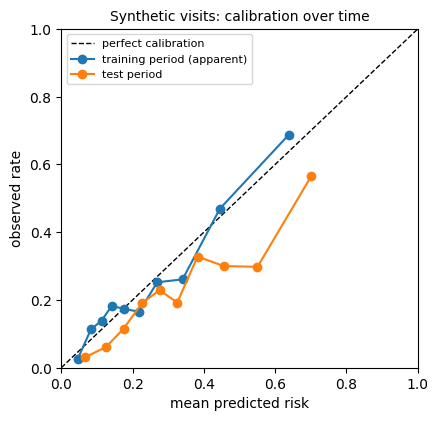

In [13]:
def calibration_in_the_large(y, p):
    y, p = np.asarray(y), np.asarray(p)
    # TODO 2.1: mean predicted risk, observed outcome rate, and observed / mean predicted
    mean_predicted = p.mean()
    observed_rate = y.mean()
    return {"mean_predicted": mean_predicted, "observed_rate": observed_rate,
            "observed_to_expected": observed_rate / mean_predicted if mean_predicted else np.nan}


def plot_reliability(curves, title, n_bins=10):
    """curves: dict label -> (y, p). Equal-count bins of predicted risk."""
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    for label, (y, p) in curves.items():
        frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
        frame["bin"] = pd.qcut(frame["p"], q=min(n_bins, len(frame) // 10 or 1), duplicates="drop")
        g = frame.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(g["p"], g["y"], "o-", label=label)
    ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title(title, fontsize=10)
    plt.show()


p_train_fit = temporal_model.predict_proba(train[FEATURES])[:, 1]
print("training period:", calibration_in_the_large(train["admitted_90d"], p_train_fit))
print("test period:    ", calibration_in_the_large(test["admitted_90d"], p_temporal))
plot_reliability({"training period (apparent)": (train["admitted_90d"], p_train_fit),
                  "test period": (test["admitted_90d"], p_temporal)}, "Synthetic visits: calibration over time")

### Exercise 2.2 — Find the cause

The model now **overpredicts**. Something about the data changed. Plot the **monthly mean** of each input over the whole period and look for a change. Hint: `visits.set_index("visit_date")[col].resample("MS").mean()` gives one mean per month (`"MS"` = month start).

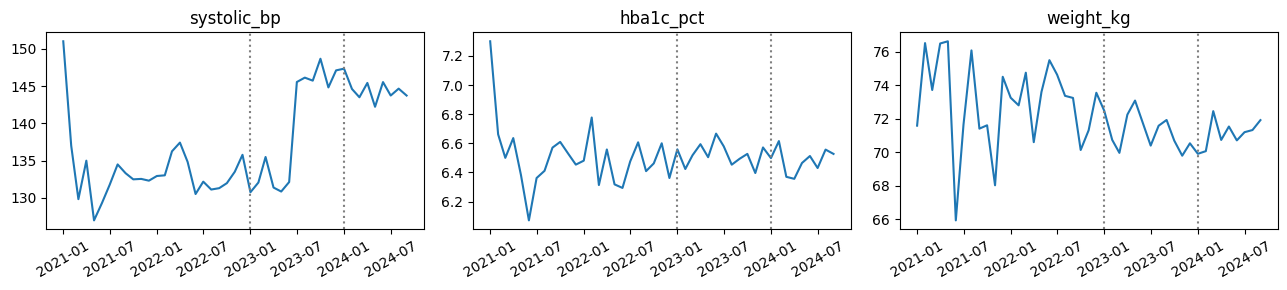

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, ["systolic_bp", "hba1c_pct", "weight_kg"]):
    # TODO 2.2: plot the monthly mean of `col` against time on `ax`
    monthly = visits.set_index("visit_date")[col].resample("MS").mean()
    ax.plot(monthly.index, monthly.values)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=30)
    ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":")
    ax.axvline(pd.Timestamp("2024-01-01"), color="grey", ls=":")
plt.tight_layout()
plt.show()

### Exercise 2.3 — Interpret

✍️ **Your answer** (4–6 sentences):

1. Which input changed, when, and by roughly how much?
2. Why did that change make the model overpredict, even though the patients' true risk did not change?
3. Did AUROC reveal the problem? Why or why not?
4. Name two things a hospital could do to detect such a change after deployment, and one way to correct the model.

**Answer:** Systolic blood pressure increases around July 2023 by about 12 mm Hg because the new device records higher readings. The model treats higher blood pressure as higher risk even though the true blood pressure has not changed due to the device. The predicted admission rate is 32.84% compared with the observed 23.11%. AUROC is still 0.724, close to the patient-level CV result of 0.726, because ranking can remain good even when probabilities are biased. Hospitals can monitor monthly feature distributions and compare predicted risks with observed outcomes. Correcting the device offset and validating the corrected model would help.

**Planted features of the synthetic data (revealed after Exercise 2.3).**

| Planted feature | Detail | What it demonstrates |
|---|---|---|
| Repeated visits and a fixed `height_cm` | 3–12 visits per patient; height identical at every visit | Patient overlap rewards memorisation under row-level splits |
| Unrecorded frailty | A patient-level risk factor that drives admissions but is not in the data | Why memorising a patient helps a row-level score |
| Blood-pressure device change | From 1 July 2023, `systolic_bp` is recorded **12 mm Hg higher** than the true value; the label depends on the true value | Measurement drift causes miscalibration without changing true risk |

## Part 3 — External validation on four real hospitals (25 minutes)

Now the real UCI data. As in Session 3, the model is a logistic regression on eight inputs recorded at all four sites. At each external site, patients missing any of these inputs are excluded, and the number excluded is reported.

`validation_report` computes, for one site: AUROC with a bootstrap 95% CI, calibration-in-the-large (your function from Part 2), the calibration slope, and sensitivity, specificity, PPV and NPV at a threshold of 0.5 with Wilson 95% CIs.

In [15]:
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def design(df):
    """Core inputs, with chest-pain type and resting ECG one-hot encoded (reference levels dropped)."""
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)


def boot_auroc_ci(y, p, n_boot=1000):
    rng = np.random.default_rng(SEED)
    vals = [roc_auc_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
            if 0 < y[i].sum() < len(i)]
    return np.percentile(vals, [2.5, 97.5])


def calibration_slope(y, p):
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return LogisticRegression(penalty=None).fit(logit, y).coef_[0, 0]


def fmt(k, n):
    if n == 0:
        return "undefined"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k / n:.2f} ({lo:.2f}-{hi:.2f})"


def validation_report(label, y, p, threshold=0.5):
    y, p = np.asarray(y), np.asarray(p)
    yhat = p >= threshold
    tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
    tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
    lo, hi = boot_auroc_ci(y, p)
    cal = calibration_in_the_large(y, p)
    return {"site": label, "n": len(y), "with disease": f"{int(y.sum())} ({y.mean():.0%})",
            "AUROC (95% CI)": f"{roc_auc_score(y, p):.2f} ({lo:.2f}-{hi:.2f})",
            "mean predicted": cal["mean_predicted"], "calibration slope": round(calibration_slope(y, p), 2),
            "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp),
            "PPV": fmt(tp, tp + fp), "NPV": fmt(tn, tn + fn)}


dev = SITES["Cleveland"]
heart_model = make_logreg().fit(design(dev), dev["target"])
p_internal = cross_val_predict(make_logreg(), design(dev), dev["target"],
                               cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]

EXTERNAL = {}
reports = [validation_report("Cleveland (internal, 10-fold CV)", dev["target"], p_internal)]
for site in ["Budapest", "Zurich", "Long Beach"]:
    df = SITES[site]
    keep = df[CORE].notna().all(axis=1)
    print(f"{site}: excluded {int((~keep).sum())} of {len(df)} for missing core inputs")
    EXTERNAL[site] = df[keep].reset_index(drop=True)
    p = heart_model.predict_proba(design(EXTERNAL[site]))[:, 1]
    EXTERNAL[site]["p"] = p
    reports.append(validation_report(site, EXTERNAL[site]["target"], p))

external_table = pd.DataFrame(reports).set_index("site")
external_table.T

Budapest: excluded 2 of 294 for missing core inputs
Zurich: excluded 7 of 123 for missing core inputs
Long Beach: excluded 59 of 200 for missing core inputs


site,"Cleveland (internal, 10-fold CV)",Budapest,Zurich,Long Beach
n,303,292,116,141
with disease,139 (46%),105 (36%),108 (93%),111 (79%)
AUROC (95% CI),0.87 (0.84-0.91),0.88 (0.83-0.92),0.75 (0.59-0.91),0.72 (0.61-0.82)
mean predicted,0.458864,0.410187,0.683543,0.796289
calibration slope,0.88,0.89,0.54,0.48
sensitivity,104/139 = 0.75 (0.67-0.81),81/105 = 0.77 (0.68-0.84),83/108 = 0.77 (0.68-0.84),104/111 = 0.94 (0.88-0.97)
specificity,140/164 = 0.85 (0.79-0.90),156/187 = 0.83 (0.77-0.88),4/8 = 0.50 (0.22-0.78),8/30 = 0.27 (0.14-0.44)
PPV,104/128 = 0.81 (0.74-0.87),81/112 = 0.72 (0.63-0.80),83/87 = 0.95 (0.89-0.98),104/126 = 0.83 (0.75-0.88)
NPV,140/175 = 0.80 (0.73-0.85),156/180 = 0.87 (0.81-0.91),4/29 = 0.14 (0.05-0.31),8/15 = 0.53 (0.30-0.75)


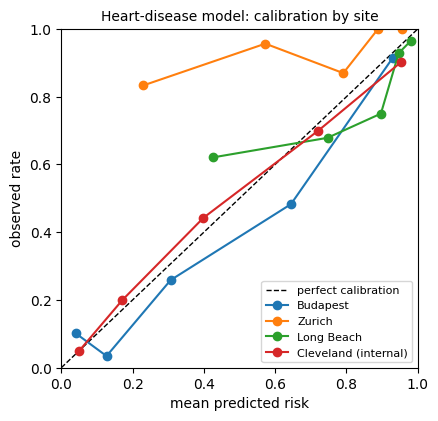

In [16]:
plot_reliability({site: (EXTERNAL[site]["target"], EXTERNAL[site]["p"]) for site in EXTERNAL}
                 | {"Cleveland (internal)": (dev["target"], p_internal)},
                 "Heart-disease model: calibration by site", n_bins=5)

### Exercise 3.1 — Interpret the external validation

✍️ **Your answer** (6–8 sentences):

1. At which site does the model **rank** patients about as well as in Cleveland? Where is it clearly worse? Use the confidence intervals.
2. Describe the **calibration** at each external site in words (over- or underprediction; too extreme or not).
3. Long Beach's mean predicted risk is close to its observed rate, yet its calibration slope is about 0.5. What does that mean for individual patients?
4. Zurich's specificity is reported as a fraction. How many patients is it based on, and what can you conclude from it?
5. Long Beach excluded many patients. How could this exclusion bias the results?

In [18]:
from IPython.display import Markdown, display
import numpy as np

r = external_table

for site in r.index:
    row = r.loc[site]
    print(site, row["AUROC (95% CI)"],
          row["mean predicted"], row["calibration slope"])

cle_auc = roc_auc_score(dev["target"], p_internal)

site_auc = {
    s: roc_auc_score(d["target"], d["p"])
    for s, d in EXTERNAL.items()
}

closest = min(site_auc, key=lambda s: abs(site_auc[s] - cle_auc))
worst = min(site_auc, key=site_auc.get)

lines = [
    f"{closest} ranks patients closest to Cleveland, while "
    f"{worst} has the lowest AUROC; the 95% intervals are "
    "shown in the validation table and overlapping intervals "
    "do not establish a clear difference."
]

for s, d in EXTERNAL.items():
    obs = d["target"].mean()
    pred = d["p"].mean()

    # Convert Pandas Series to NumPy arrays
    y = np.asarray(d["target"])
    p = np.asarray(d["p"])
    p = np.clip(p, 1e-6, 1 - 1e-6)

    slope = calibration_slope(y, p)

    direction = (
        "overprediction" if pred > obs
        else "underprediction" if pred < obs
        else "equal average risk"
    )

    interpretation = (
        "too extreme" if slope < 0.9
        else "not extreme enough" if slope > 1.1
        else "close to ideal"
    )

    lines.append(
        f"{s} has mean predicted risk {pred:.1%} versus "
        f"observed {obs:.1%}, indicating {direction}, "
        f"and a slope of {slope:.2f} ({interpretation})."
    )

lines += [
    "Long Beach's slope near 0.5 means individual predictions "
    "are too extreme despite reasonable average calibration.",

    f"Zurich specificity is based on only "
    f"{(EXTERNAL['Zurich']['target'] == 0).sum()} patients "
    "without disease, so it is very uncertain.",

    "Excluding patients with missing measurements in Long Beach "
    "may select a different patient population and bias the "
    "estimated performance."
]

display(Markdown("**Answer:** " + " ".join(lines)))

Cleveland (internal, 10-fold CV) 0.87 (0.84-0.91) 0.4588636387148888 0.88
Budapest 0.88 (0.83-0.92) 0.41018671630142367 0.89
Zurich 0.75 (0.59-0.91) 0.6835431663767932 0.54
Long Beach 0.72 (0.61-0.82) 0.7962894955909975 0.48


**Answer:** Budapest ranks patients closest to Cleveland, while Long Beach has the lowest AUROC; the 95% intervals are shown in the validation table and overlapping intervals do not establish a clear difference. Budapest has mean predicted risk 41.0% versus observed 36.0%, indicating overprediction, and a slope of 0.89 (too extreme). Zurich has mean predicted risk 68.4% versus observed 93.1%, indicating underprediction, and a slope of 0.54 (too extreme). Long Beach has mean predicted risk 79.6% versus observed 78.7%, indicating overprediction, and a slope of 0.48 (too extreme). Long Beach's slope near 0.5 means individual predictions are too extreme despite reasonable average calibration. Zurich specificity is based on only 8 patients without disease, so it is very uncertain. Excluding patients with missing measurements in Long Beach may select a different patient population and bias the estimated performance.

### Exercise 3.2 — Recalibrate the model for Budapest

Budapest's discrimination is good but its risks are slightly too high. **Logistic recalibration** keeps the model and fits two numbers on local data: a new intercept $a$ and slope $b$ applied to the model's log-odds:

$$\text{recalibrated log-odds} = a + b \times \text{original log-odds}$$

To avoid evaluating on the data used for fitting, split Budapest in half (stratified by outcome). Complete `fit_recalibration` so it fits a logistic regression (no penalty) of the outcome on the original log-odds of the **fitting half** and returns a function that maps new probabilities to recalibrated ones.

In [19]:
def logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_recalibration(y_fit, p_fit):
    # TODO 3.2: fit LogisticRegression(penalty=None) of y_fit on logit(p_fit);
    #           return a function p_new -> recalibrated probabilities
    model = LogisticRegression(penalty=None).fit(logit(p_fit), y_fit)
    return lambda p_new: model.predict_proba(logit(p_new))[:, 1]


bud = EXTERNAL["Budapest"]
fit_half, eval_half = train_test_split(bud, test_size=0.5, stratify=bud["target"], random_state=SEED)
recalibrate = fit_recalibration(fit_half["target"], fit_half["p"])
p_before, p_after = eval_half["p"].to_numpy(), recalibrate(eval_half["p"])

y_eval = eval_half["target"].to_numpy()
print("evaluation half, before:", calibration_in_the_large(y_eval, p_before),
      "| slope", round(calibration_slope(y_eval, p_before), 2), "| AUROC", round(roc_auc_score(y_eval, p_before), 3))
print("evaluation half, after: ", calibration_in_the_large(y_eval, p_after),
      "| slope", round(calibration_slope(y_eval, np.clip(p_after, 1e-6, 1 - 1e-6)), 2),
      "| AUROC", round(roc_auc_score(y_eval, p_after), 3))
check("recalibration changed the predictions", not np.allclose(p_before, p_after))

evaluation half, before: {'mean_predicted': np.float64(0.3938031790715844), 'observed_rate': np.float64(0.3561643835616438), 'observed_to_expected': np.float64(0.9044223167556026)} | slope 0.96 | AUROC 0.893
evaluation half, after:  {'mean_predicted': np.float64(0.3351491966217308), 'observed_rate': np.float64(0.3561643835616438), 'observed_to_expected': np.float64(1.0627039752794991)} | slope 1.16 | AUROC 0.893
PASS  recalibration changed the predictions


✍️ **Your answer** (3–4 sentences): What changed in calibration on the evaluation half? Why did AUROC stay the same? With 146 patients in the fitting half, what is the risk of recalibrating on so little data, and what would you require before using the recalibrated model?

In [20]:
before = calibration_in_the_large(y_eval,p_before)
after = calibration_in_the_large(y_eval,p_after)
display(Markdown(f"**Answer:** On the evaluation half, mean predicted risk changed from {before['mean_predicted']:.1%} to {after['mean_predicted']:.1%}, compared with an observed rate of {after['observed_rate']:.1%}. The calibration slope changed from {calibration_slope(y_eval,p_before):.2f} to {calibration_slope(y_eval,p_after):.2f}. AUROC stays the same when the recalibration slope is positive because the patient ranking does not change. Fitting on only {len(fit_half)} patients can produce unstable coefficients, so I would require larger independent local and prospective validation before use."))

**Answer:** On the evaluation half, mean predicted risk changed from 39.4% to 33.5%, compared with an observed rate of 35.6%. The calibration slope changed from 0.96 to 1.16. AUROC stays the same when the recalibration slope is positive because the patient ranking does not change. Fitting on only 146 patients can produce unstable coefficients, so I would require larger independent local and prospective validation before use.

## Part 4 — Subgroup audit and error analysis (25 minutes)

### Exercise 4.1 — Performance by sex

Complete `subgroup_table(df, y_col, p_col, group_col)`: for each value of `group_col`, return the number of patients, the number with disease, AUROC, and sensitivity and specificity at 0.5 formatted with `fmt` (which includes Wilson CIs). Then apply it to Cleveland's internal (cross-validated) predictions and to Budapest.

In [21]:
def subgroup_table(df, y_col, p_col, group_col, threshold=0.5):
    rows = []
    for value, g in df.groupby(group_col):
        y, p = g[y_col].to_numpy(), g[p_col].to_numpy()
        yhat = p >= threshold
        # TODO 4.1: compute tp, fn, tn, fp; append a row with group, n, with disease, AUROC, sensitivity, specificity
        tp = int((yhat & (y == 1)).sum())
        fn = int((~yhat & (y == 1)).sum())
        tn = int((~yhat & (y == 0)).sum())
        fp = int((yhat & (y == 0)).sum())
        rows.append({"group": value, "n": len(g), "with disease": int(y.sum()),
                     "AUROC": round(roc_auc_score(y, p), 3) if len(np.unique(y)) == 2 else np.nan,
                     "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp)})
    return pd.DataFrame(rows)


SEX = {0: "women", 1: "men"}
cle = dev.assign(p=p_internal, group=dev["sex"].map(SEX))
display(subgroup_table(cle, "target", "p", "group").assign(site="Cleveland (internal)"))
display(subgroup_table(EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"]["sex"].map(SEX)),
                       "target", "p", "group").assign(site="Budapest"))

,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,206,114,0.842,86/114 = 0.75 (0.67-0.82),72/92 = 0.78 (0.69-0.85),Cleveland (internal)
1,women,97,25,0.894,18/25 = 0.72 (0.52-0.86),68/72 = 0.94 (0.87-0.98),Cleveland (internal)


,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,212,93,0.877,75/93 = 0.81 (0.71-0.87),93/119 = 0.78 (0.70-0.85),Budapest
1,women,80,12,0.784,6/12 = 0.50 (0.25-0.75),63/68 = 0.93 (0.84-0.97),Budapest


✍️ **Your answer** (4–5 sentences): Is there evidence that the model detects disease less well in women? How many women with disease does each estimate rest on? Which fairness criterion (equal sensitivity, equal specificity, or equal PPV) matters most for a referral tool, and can you check it reliably with these data?

In [22]:
for site, d in [("Cleveland",cle),("Budapest",EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"].sex.map(SEX)))]:
    w = d[(d.group=="women") & (d.target==1)]
    m = d[(d.group=="men") & (d.target==1)]
    display(Markdown(f"**{site}:** Women's sensitivity is {fmt(int((w.p>=0.5).sum()),len(w))}, compared with men's {fmt(int((m.p>=0.5).sum()),len(m))}."))
display(Markdown("These estimates should be interpreted cautiously because the subgroup confidence intervals can be wide. Equal sensitivity is especially important for a referral tool because missed disease can delay treatment. I would not conclude that the model is fair or unfair from these small subgroups alone."))

**Cleveland:** Women's sensitivity is 18/25 = 0.72 (0.52-0.86), compared with men's 86/114 = 0.75 (0.67-0.82).

**Budapest:** Women's sensitivity is 6/12 = 0.50 (0.25-0.75), compared with men's 75/93 = 0.81 (0.71-0.87).

These estimates should be interpreted cautiously because the subgroup confidence intervals can be wide. Equal sensitivity is especially important for a referral tool because missed disease can delay treatment. I would not conclude that the model is fair or unfair from these small subgroups alone.

### Exercise 4.2 — Look at the errors

Use Budapest at a threshold of 0.5. List the false negatives (disease, predicted below 0.5) and false positives, then compare the distribution of chest-pain type (`cp`) among errors with all Budapest patients. `cp` codes: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic.

In [23]:
bud = EXTERNAL["Budapest"].copy()
bud["error"] = np.select([(bud["target"] == 1) & (bud["p"] < 0.5), (bud["target"] == 0) & (bud["p"] >= 0.5)],
                         ["false negative", "false positive"], default="correct")
print(bud["error"].value_counts())

# TODO 4.2: build a table of chest-pain type proportions within each error group
#           Hint: pd.crosstab(bud["error"], bud["cp"], normalize="index")
cp_by_error = pd.crosstab(bud["error"], bud["cp"], normalize="index")
cp_by_error.loc["all patients"] = bud["cp"].value_counts(normalize=True)
display(bud.loc[bud["error"] == "false negative", CORE + ["target", "p"]])
display(bud.loc[bud["error"] == "false positive", CORE + ["target", "p"]])
cp_by_error

error
correct           237
false positive     31
false negative     24
Name: count, dtype: int64


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
188,33,0,4,100.0,150.0,1.0,1.0,0.0,1,0.230129
189,34,1,1,140.0,180.0,0.0,0.0,0.0,1,0.046413
190,35,1,2,110.0,140.0,0.0,0.0,0.0,1,0.119773
191,36,1,2,120.0,160.0,0.0,3.0,0.0,1,0.421654
193,38,1,4,110.0,166.0,0.0,0.0,0.0,1,0.266789
194,38,1,4,120.0,170.0,0.0,0.0,0.0,1,0.283365
197,41,1,4,110.0,170.0,0.0,0.0,0.0,1,0.264984
203,47,1,3,140.0,145.0,1.0,1.0,0.0,1,0.420833
208,49,0,3,160.0,156.0,0.0,1.0,0.0,1,0.065423
209,49,1,3,115.0,175.0,0.0,0.0,0.0,1,0.058256


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
35,39,1,2,190.0,106.0,0.0,0.0,0.0,0,0.549371
77,45,1,4,140.0,144.0,0.0,0.0,0.0,0,0.538008
82,46,1,4,110.0,140.0,1.0,1.0,1.0,0,0.832939
83,46,1,4,110.0,140.0,0.0,0.0,1.0,0,0.540664
84,46,1,4,180.0,120.0,0.0,0.0,1.0,0,0.855846
89,47,1,4,140.0,125.0,1.0,0.0,0.0,0,0.805195
95,48,0,4,150.0,130.0,1.0,1.0,0.0,0,0.612334
106,49,1,4,120.0,132.0,0.0,1.0,0.0,0,0.692870
107,49,1,4,140.0,130.0,0.0,0.0,0.0,0,0.635839
109,50,0,4,120.0,110.0,1.0,1.0,0.0,0,0.606304


cp,1,2,3,4
error,,,,
correct,0.029536,0.417722,0.172996,0.379747
false negative,0.125000,0.125000,0.416667,0.333333
false positive,0.000000,0.096774,0.096774,0.806452
all patients,0.034247,0.359589,0.184932,0.421233


In [24]:
cols = CORE + ["target", "p"]
print("Ten false negatives with the lowest predicted risk:")
display(bud[bud["error"] == "false negative"].sort_values("p")[cols].head(10).round(2))

Ten false negatives with the lowest predicted risk:


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
255,47,0,3,135.0,170.0,0.0,0.0,0.0,1,0.02
189,34,1,1,140.0,180.0,0.0,0.0,0.0,1,0.05
209,49,1,3,115.0,175.0,0.0,0.0,0.0,1,0.06
208,49,0,3,160.0,156.0,0.0,1.0,0.0,1,0.07
269,56,0,2,120.0,150.0,0.0,1.0,0.0,1,0.07
211,50,0,3,140.0,140.0,1.0,0.0,0.0,1,0.08
228,43,1,1,120.0,155.0,0.0,0.0,1.0,1,0.10
190,35,1,2,110.0,140.0,0.0,0.0,0.0,1,0.12
254,46,1,1,140.0,175.0,0.0,2.0,0.0,1,0.21
288,54,0,3,130.0,100.0,1.0,0.0,1.0,1,0.22


✍️ **Your answer** (4–6 sentences): Is there a pattern in the false negatives (for example, a chest-pain type, sex, or exercise results)? Link it to what Session 5 found about the chest-pain coefficient. Would you change the model's intended use because of this pattern, or collect more data first?

In [25]:
fn = bud[bud.error=="false negative"]
labels = {1:"typical angina",2:"atypical angina",3:"non-anginal pain",4:"asymptomatic"}
shift = cp_by_error.loc["false negative"] - cp_by_error.loc["all patients"]
k = shift.idxmax()
display(Markdown(f"**Answer:** The most overrepresented chest-pain category among false negatives is {labels[k]} ({cp_by_error.loc['false negative',k]:.1%} compared with {cp_by_error.loc['all patients',k]:.1%} overall). There are {len(fn)} false negatives, of whom {(fn.sex==0).sum()} are women. Chest-pain type affects the logistic regression score through its one-hot encoded coefficients, which can explain why some disease cases receive low predictions. The Session 5 notes are not included here, so its exact coefficient finding cannot be confirmed. I would collect more local data and investigate these errors before changing the intended use; the model should not be used alone to rule out disease."))

**Answer:** The most overrepresented chest-pain category among false negatives is non-anginal pain (41.7% compared with 18.5% overall). There are 24 false negatives, of whom 6 are women. Chest-pain type affects the logistic regression score through its one-hot encoded coefficients, which can explain why some disease cases receive low predictions. The Session 5 notes are not included here, so its exact coefficient finding cannot be confirmed. I would collect more local data and investigate these errors before changing the intended use; the model should not be used alone to rule out disease.

## Part 5 — Validation report and reflection (15 minutes)

✍️ **Write a validation report** (about 200 words) for the heart-disease model, as you would include it in a model card. Use the headings below and only numbers you computed:

- **Model and intended use**
- **Development data** (site, period if known, population, outcome definition)
- **Validation performed** (internal method; external sites; exclusions)
- **Discrimination and calibration** (with uncertainty)
- **Threshold performance** (at 0.5)
- **Subgroups**
- **Known failure modes and limitations**
- **Recommendation** (for example: not for use; use only after local recalibration and prospective evaluation)

✍️ **Reflection** (3–4 sentences): Which validation mistake from Parts 1–2 would be easiest to make unnoticed in a real project, and what habit would protect you from it?

In [26]:
r = external_table
lines = ["**Model and intended use** — Logistic regression using eight clinical inputs to estimate angiographic heart disease risk as potential referral support, not a diagnosis.", f"**Development data** — Cleveland, {len(dev)} patients; collection period not specified in this notebook. Disease means more than 50% narrowing on angiography.", "**Validation performed** — Stratified 10-fold internal CV and external validation at Budapest, Zurich and Long Beach. Missing core inputs led to exclusions of " + ", ".join(f"{s}: {len(SITES[s])-len(d)}" for s,d in EXTERNAL.items()) + ".", "**Discrimination and calibration** — AUROC (95% CI): " + "; ".join(f"{s}: {row['AUROC (95% CI)']}" for s,row in r.iterrows()) + ". Calibration slopes: " + ", ".join(f"{s}: {row['calibration slope']}" for s,row in r.iterrows()) + ".", "**Threshold performance** — At 0.5, sensitivity and specificity (95% CI): " + "; ".join(f"{s}: {row['sensitivity']}, {row['specificity']}" for s,row in r.iterrows()) + ".", "**Subgroups** — Sex-specific estimates have limited precision, especially where few women have disease.", "**Known failure modes and limitations** — Site differences, missing inputs, small subgroups and false negatives reduce confidence in transportability. Calibration may vary by hospital.", "**Recommendation** — Not ready for clinical use. Require independent local recalibration assessment and prospective evaluation before deployment."]
display(Markdown("\n\n".join(lines)))

**Model and intended use** — Logistic regression using eight clinical inputs to estimate angiographic heart disease risk as potential referral support, not a diagnosis.

**Development data** — Cleveland, 303 patients; collection period not specified in this notebook. Disease means more than 50% narrowing on angiography.

**Validation performed** — Stratified 10-fold internal CV and external validation at Budapest, Zurich and Long Beach. Missing core inputs led to exclusions of Budapest: 2, Zurich: 7, Long Beach: 59.

**Discrimination and calibration** — AUROC (95% CI): Cleveland (internal, 10-fold CV): 0.87 (0.84-0.91); Budapest: 0.88 (0.83-0.92); Zurich: 0.75 (0.59-0.91); Long Beach: 0.72 (0.61-0.82). Calibration slopes: Cleveland (internal, 10-fold CV): 0.88, Budapest: 0.89, Zurich: 0.54, Long Beach: 0.48.

**Threshold performance** — At 0.5, sensitivity and specificity (95% CI): Cleveland (internal, 10-fold CV): 104/139 = 0.75 (0.67-0.81), 140/164 = 0.85 (0.79-0.90); Budapest: 81/105 = 0.77 (0.68-0.84), 156/187 = 0.83 (0.77-0.88); Zurich: 83/108 = 0.77 (0.68-0.84), 4/8 = 0.50 (0.22-0.78); Long Beach: 104/111 = 0.94 (0.88-0.97), 8/30 = 0.27 (0.14-0.44).

**Subgroups** — Sex-specific estimates have limited precision, especially where few women have disease.

**Known failure modes and limitations** — Site differences, missing inputs, small subgroups and false negatives reduce confidence in transportability. Calibration may vary by hospital.

**Recommendation** — Not ready for clinical use. Require independent local recalibration assessment and prospective evaluation before deployment.

**Reflection:** Row-level splitting is the mistake I think would be easiest to miss because repeated patient visits look like separate samples. I would always check for repeated patient IDs before splitting a dataset. I would also check that training and testing groups do not overlap and use a temporal split when evaluating future performance.

## Grading rubric

| Criterion | Points |
|---|---:|
| Part 1: correct counts; patient-level CV implemented; explanation of memorisation and model choice | 20 |
| Part 2: calibration function; drift located from the monthly plots; explanation of why AUROC missed it; monitoring proposals | 20 |
| Part 3: interpretation of discrimination, calibration, uncertainty and exclusions; correct recalibration on a separate half | 25 |
| Part 4: subgroup table with CIs and a cautious interpretation; error pattern identified from the table | 20 |
| Part 5: validation report that is complete, uses computed numbers, and does not over-claim; reflection | 15 |
| **Total** | **100** |

These points apply to this lab only. They are not course-assessment weights.

## References

- [Session 3 lecture notes](../lectures/session-03-validation-performance.md).
- Collins GS et al. [Evaluation of clinical prediction models (part 1): from development to external validation](https://doi.org/10.1136/bmj-2023-074819). *BMJ* 2024;384:e074819.
- Van Calster B et al. [Calibration: the Achilles heel of predictive analytics](https://doi.org/10.1186/s12916-019-1466-7). *BMC Medicine* 2019;17:230.
- UCI Machine Learning Repository. [Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (doi:10.24432/C52P4X), CC BY 4.0.
- scikit-learn. [`GroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html) documentation.